In [1]:
import sys
!{sys.executable} -m pip install imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'esthétique des graphiques
sns.set_theme(style="whitegrid")

# 1. Chargement des données
# Assurez-vous que le fichier creditcard.csv est dans le même dossier que votre notebook
df = pd.read_csv('creditcard.csv')

# ==========================================
# PARTIE 1 : STATISTIQUES DESCRIPTIVES & VALEURS MANQUANTES
# ==========================================

print("--- 1. Informations générales du Dataset ---")
df.info()



--- 1. Informations générales du Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20

In [ ]:
print("\n--- 2. Vérification des valeurs manquantes ---")
# On somme les valeurs nulles par colonne et on affiche celles qui en ont
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
if missing_values.max() == 0:
    print("Excellente nouvelle : Le dataset ne contient aucune valeur manquante.")
else:
    pass



--- 2. Vérification des valeurs manquantes ---
Series([], dtype: int64)
Excellente nouvelle : Le dataset ne contient aucune valeur manquante.


In [5]:
print("\n--- 3. Statistiques descriptives (Focus sur Time et Amount) ---")
# Les variables V1 à V28 sont déjà standardisées par l'ACP, leur moyenne est proche de 0
print(df[['Time', 'Amount']].describe())


--- 3. Statistiques descriptives (Focus sur Time et Amount) ---
                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


# ==========================================
# PARTIE 2 : ANALYSE VISUELLE ET VALEURS ABERRANTES
# ==========================================

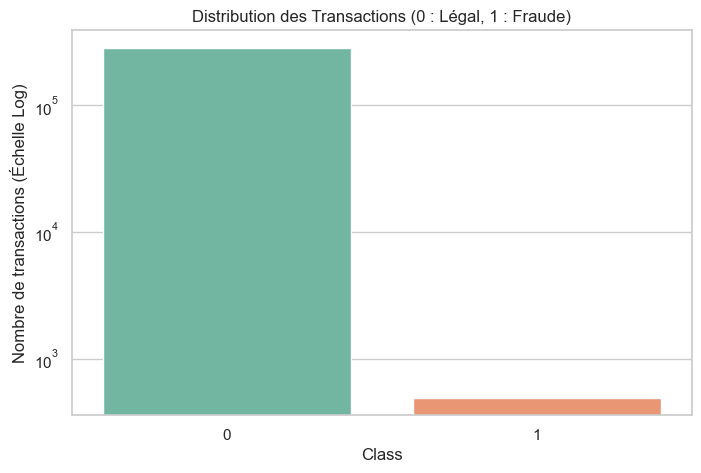

Pourcentage de fraudes : 0.173%


In [7]:
# A. Visualisation du déséquilibre des classes
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='Class', data=df, hue='Class', palette='Set2', legend=False)
plt.title('Distribution des Transactions (0 : Légal, 1 : Fraude)')
# On utilise une échelle logarithmique sur l'axe Y car la différence est massive
plt.yscale('log')
plt.ylabel('Nombre de transactions (Échelle Log)')
plt.show()

# Affichage des pourcentages exacts
frauds = df[df['Class'] == 1]
normal = df[df['Class'] == 0]
print(f"Pourcentage de fraudes : {round(len(frauds)/len(df) * 100, 3)}%")



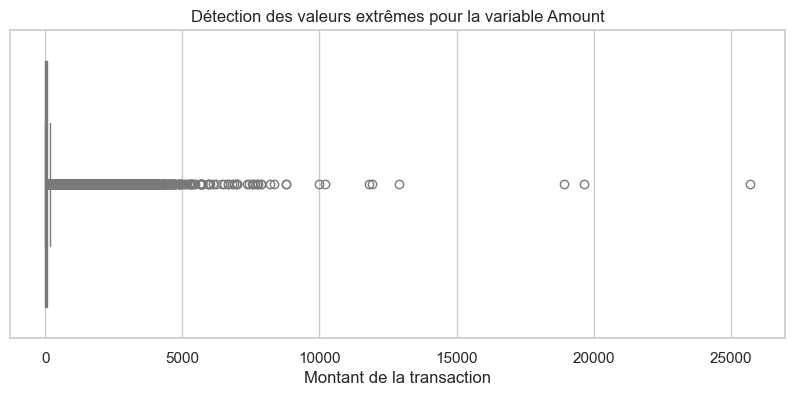

In [ ]:
# B. Étude des valeurs extrêmes (Outliers) sur le Montant (Amount)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Amount'], color='lightblue')
plt.title('Détection des valeurs extrêmes pour la variable Amount')
plt.xlabel('Montant de la transaction')
plt.show()


# ==========================================
# PARTIE 3 : ANALYSE BI-VARIÉE 
# ==========================================
# discrétiser la variable 'Amount' pour étudier son lien avec 'Class'


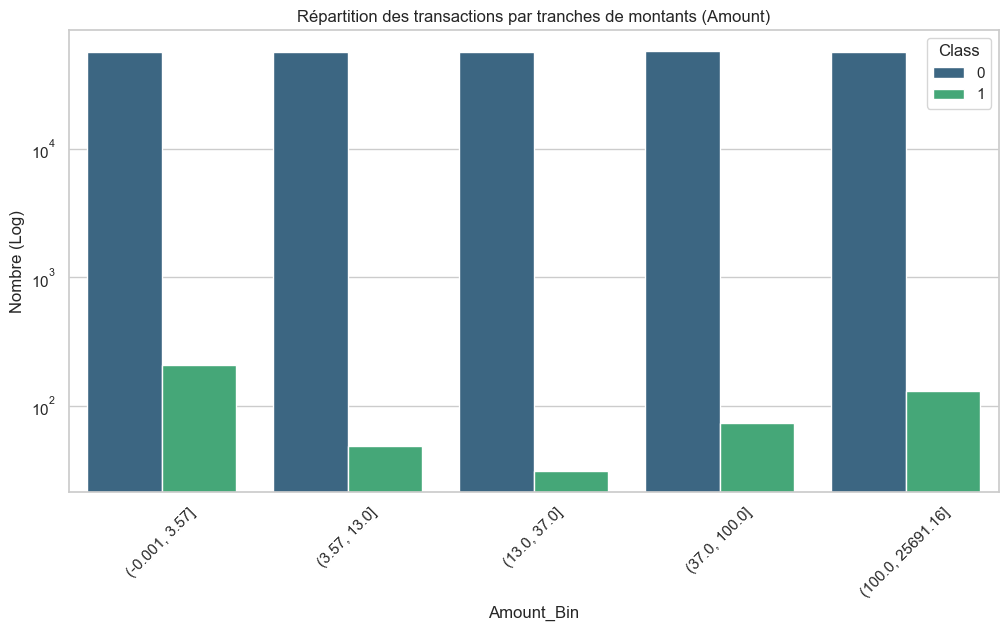

In [9]:
# Création de quantiles (par exemple 5 tranches de montants)
# duplicates='drop' permet d'éviter les erreurs si trop de montants sont à 0
df['Amount_Bin'] = pd.qcut(df['Amount'], q=5, duplicates='drop')

plt.figure(figsize=(12, 6))
# On observe la proportion de fraudes dans chaque tranche de montant
sns.countplot(x='Amount_Bin', hue='Class', data=df, palette='viridis')
plt.title('Répartition des transactions par tranches de montants (Amount)')
plt.yscale('log') # Échelle log pour bien voir les fraudes
plt.xticks(rotation=45)
plt.ylabel('Nombre (Log)')
plt.show()

# Nettoyage : On supprime la variable temporaire 'Amount_Bin' pour ne pas polluer 
# la suite du projet (les modèles préfèrent les variables numériques continues)
df = df.drop(['Amount_Bin'], axis=1)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# ==========================================
# ÉTAPE 2 : SÉPARATION ET STANDARDISATION
# ==========================================

# 1. Séparation des features (X) et de la cible (y)
X = df.drop(['Class'], axis=1)
y = df['Class']

# 2. Partitionnement des données (Train / Test)
# Le paramètre 'stratify=y' est CRUCIAL ici : il garantit que la proportion de 0.172% 
# de fraudes est rigoureusement la même dans le bloc Train et dans le bloc Test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Dimensions de l'ensemble d'entraînement (Train) : {X_train.shape}")
print(f"Dimensions de l'ensemble de validation (Test)    : {X_test.shape}")

# 3. Initialisation du RobustScaler
robust_scaler = RobustScaler()

# 4. Ajustement et transformation des variables d'échelle (Amount et Time)
# On applique le fit_transform uniquement sur le bloc Train
X_train['Amount'] = robust_scaler.fit_transform(X_train['Amount'].values.reshape(-1, 1))
X_train['Time'] = robust_scaler.fit_transform(X_train['Time'].values.reshape(-1, 1))

# On applique uniquement le transform sur le bloc Test (aucune fuite de données !)
X_test['Amount'] = robust_scaler.transform(X_test['Amount'].values.reshape(-1, 1))
X_test['Time'] = robust_scaler.transform(X_test['Time'].values.reshape(-1, 1))

print("\nStandardisation réussie. Aperçu des données d'entraînement standardisées :")
print(X_train[['Time', 'Amount']].head())

Dimensions de l'ensemble d'entraînement (Train) : (227845, 30)
Dimensions de l'ensemble de validation (Test)    : (56962, 30)

Standardisation réussie. Aperçu des données d'entraînement standardisées :
            Time    Amount
265518  0.905774 -0.204315
180305  0.465984 -0.264579
42664  -0.512286  2.130828
198723  0.561678 -0.221294
82325  -0.298886  0.892136


Étape 3 : Création des jeux de données

In [11]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
from collections import Counter

print("Distribution originale dans le Train set :", Counter(y_train))

# ==========================================
# 1. SOUS-ÉCHANTILLONNAGE (Under-sampling)
# ==========================================
print("\n--- 1. Application du Random Under-sampling ---")
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("Nouvelle distribution (Under-sampling) :", Counter(y_train_rus))

Distribution originale dans le Train set : Counter({0: 227451, 1: 394})

--- 1. Application du Random Under-sampling ---
Nouvelle distribution (Under-sampling) : Counter({0: 394, 1: 394})


In [12]:
# ==========================================
# 2. SUR-ÉCHANTILLONNAGE (Over-sampling avec SMOTE)
# ==========================================
print("\n--- 2. Application de SMOTE ---")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("Nouvelle distribution (SMOTE) :", Counter(y_train_smote))


--- 2. Application de SMOTE ---
Nouvelle distribution (SMOTE) : Counter({0: 227451, 1: 227451})


In [13]:
# ==========================================
# 3. TECHNIQUE HYBRIDE (SMOTE + Tomek Links)
# ==========================================
print("\n--- 3. Application de SMOTETomek (Hybride) ---")
# ATTENTION : Cette étape peut prendre 2 à 5 minutes selon la puissance de votre machine
smote_tomek = SMOTETomek(random_state=42)
X_train_hybrid, y_train_hybrid = smote_tomek.fit_resample(X_train, y_train)
print("Nouvelle distribution (SMOTETomek) :", Counter(y_train_hybrid))


--- 3. Application de SMOTETomek (Hybride) ---
Nouvelle distribution (SMOTETomek) : Counter({0: 227451, 1: 227451})


In [14]:
# ==========================================
# 4. COST-SENSITIVE LEARNING
# ==========================================
print("\n--- 4. Cost-Sensitive Learning ---")
print("Aucune transformation requise ici. Nous utiliserons X_train et y_train originaux")
print("avec le paramètre 'class_weight=\"balanced\"' lors de l'entraînement des modèles.")


--- 4. Cost-Sensitive Learning ---
Aucune transformation requise ici. Nous utiliserons X_train et y_train originaux
avec le paramètre 'class_weight="balanced"' lors de l'entraînement des modèles.


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

# 1. On définit un modèle de base
model_lr = LogisticRegression(max_iter=1000, random_state=42)

# Modèle spécifique pour le Cost-Sensitive (on lui ajoute class_weight='balanced')
model_lr_cost_sensitive = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

# 2. On crée un dictionnaire contenant nos 4 environnements de test
datasets = {
    "1. Baseline (Données Originales + Cost-Sensitive)": (X_train, y_train, model_lr_cost_sensitive),
    "2. Sous-échantillonnage (Under-sampling)": (X_train_rus, y_train_rus, model_lr),
    "3. Sur-échantillonnage (SMOTE)": (X_train_smote, y_train_smote, model_lr),
    "4. Hybride (SMOTETomek)": (X_train_hybrid, y_train_hybrid, model_lr)
}

# 3. Boucle d'entraînement et d'évaluation
print("=== DÉBUT DE L'ÉTUDE COMPARATIVE ===")

for nom, (X_tr, y_tr, modele_a_utiliser) in datasets.items():
    print(f"\n--- Évaluation de la méthode : {nom} ---")
    
    # Entraînement
    modele_a_utiliser.fit(X_tr, y_tr)
    
    # Prédiction sur le jeu de TEST (qui n'a jamais été modifié !)
    y_pred = modele_a_utiliser.predict(X_test)
    y_prob = modele_a_utiliser.predict_proba(X_test)[:, 1] # Probabilités pour l'AUPRC
    
    # Affichage de la matrice de confusion
    print("Matrice de Confusion :")
    print(confusion_matrix(y_test, y_pred))
    
    # Affichage du rapport (Recall, Precision, F1)
    print("\nRapport de Classification :")
    print(classification_report(y_test, y_pred))
    
    # Calcul de l'AUPRC
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    auprc = auc(recall, precision)
    print(f"Score AUPRC : {auprc:.4f}")
    print("-" * 50)

=== DÉBUT DE L'ÉTUDE COMPARATIVE ===

--- Évaluation de la méthode : 1. Baseline (Données Originales + Cost-Sensitive) ---
Matrice de Confusion :
[[56246   618]
 [   11    87]]

Rapport de Classification :
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.89      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962

Score AUPRC : 0.7587
--------------------------------------------------

--- Évaluation de la méthode : 2. Sous-échantillonnage (Under-sampling) ---
Matrice de Confusion :
[[55031  1833]
 [    8    90]]

Rapport de Classification :
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg     

In [ ]:
from sklearn.ensemble import RandomForestClassifier


print("=== ÉTUDE AVEC RANDOM FOREST ===")

# 1. On définit le nouveau modèle
# n_estimators=100 (nombre d'arbres), n_jobs=-1 (utilise tous les cœurs du processeur pour aller plus vite)
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Modèle spécifique pour le Cost-Sensitive
model_rf_cost_sensitive = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)

# 2. On met à jour le dictionnaire avec les Random Forests
datasets_rf = {
    "1. Baseline (Cost-Sensitive)": (X_train, y_train, model_rf_cost_sensitive),
    "2. Sous-échantillonnage": (X_train_rus, y_train_rus, model_rf),
    "3. Sur-échantillonnage (SMOTE)": (X_train_smote, y_train_smote, model_rf),
    "4. Hybride (SMOTETomek)": (X_train_hybrid, y_train_hybrid, model_rf)
}

# 3. On relance la boucle d'évaluation
for nom, (X_tr, y_tr, modele_a_utiliser) in datasets_rf.items():
    print(f"\n--- Évaluation avec Random Forest : {nom} ---")
    
    # Entraînement
    modele_a_utiliser.fit(X_tr, y_tr)
    
    # Prédiction
    y_pred = modele_a_utiliser.predict(X_test)
    y_prob = modele_a_utiliser.predict_proba(X_test)[:, 1] 
    
    # Résultats
    print(confusion_matrix(y_test, y_pred))
    
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    auprc = auc(recall, precision)
    print(f"Score AUPRC : {auprc:.4f}")
    print("-" * 50)

=== ÉTUDE AVEC RANDOM FOREST ===

--- Évaluation avec Random Forest : 1. Baseline (Cost-Sensitive) ---
[[56861     3]
 [   25    73]]
Score AUPRC : 0.8532
--------------------------------------------------

--- Évaluation avec Random Forest : 2. Sous-échantillonnage ---
[[54528  2336]
 [    8    90]]
Score AUPRC : 0.7520
--------------------------------------------------

--- Évaluation avec Random Forest : 3. Sur-échantillonnage (SMOTE) ---
[[56853    11]
 [   17    81]]
Score AUPRC : 0.8690
--------------------------------------------------

--- Évaluation avec Random Forest : 4. Hybride (SMOTETomek) ---
[[56853    11]
 [   17    81]]
Score AUPRC : 0.8690
--------------------------------------------------


In [17]:
!pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 5.6 MB/s eta 0:00:19
    --------------------------------------- 1.3/101.7 MB 4.5 MB/s eta 0:00:23
    --------------------------------------- 2.4/101.7 MB 3.9 MB/s eta 0:00:26
   - -------------------------------------- 3.4/101.7 MB 4.3 MB/s eta 0:00:23
   - -------------------------------------- 5.0/101.7 MB 5.0 MB/s eta 0:00:20
   -- ------------------------------------- 6.0/101.7 MB 5.0 MB/s eta 0:00:20
   -- ------------------------------------- 7.1/101.7 MB 5.1 MB/s eta 0:00:19
   --- ------------------------------------ 8.4/101.7 MB 5.3 MB/s eta 0:00:18
   --- ------------------------------------ 9.7/101.7 MB 5.4 MB/s eta 0:00:17
   ---- ----------------------------------- 10.7/101.7 MB 5.4 MB/s eta 0:00:17
   ---- ----------------------------------- 12.1/101.7 MB 5.4 MB/s eta 0:00:17
   ----- ---------------------------------- 13.1/101.7 MB 5.4 MB/s et

In [18]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

print("=== ÉTUDE AVEC XGBOOST ===")

# 1. Calcul du poids pour le Cost-Sensitive Learning
# Formule : Nombre d'exemples normaux (0) / Nombre de fraudes (1) dans le Train Set
ratio_poids = len(y_train[y_train==0]) / len(y_train[y_train==1])

# 2. Définition des modèles XGBoost
# random_state assure la reproductibilité, n_jobs=-1 utilise tout le processeur
model_xgb = XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')

# Modèle spécifique Cost-Sensitive avec le paramètre scale_pos_weight
model_xgb_cs = XGBClassifier(scale_pos_weight=ratio_poids, random_state=42, n_jobs=-1, eval_metric='logloss')

# 3. Dictionnaire de nos 4 environnements
datasets_xgb = {
    "1. Baseline (Cost-Sensitive)": (X_train, y_train, model_xgb_cs),
    "2. Sous-échantillonnage": (X_train_rus, y_train_rus, model_xgb),
    "3. Sur-échantillonnage (SMOTE)": (X_train_smote, y_train_smote, model_xgb),
    "4. Hybride (SMOTETomek)": (X_train_hybrid, y_train_hybrid, model_xgb)
}

# 4. Boucle d'évaluation
for nom, (X_tr, y_tr, modele_a_utiliser) in datasets_xgb.items():
    print(f"\n--- Évaluation avec XGBoost : {nom} ---")
    
    # Entraînement
    modele_a_utiliser.fit(X_tr, y_tr)
    
    # Prédiction
    y_pred = modele_a_utiliser.predict(X_test)
    y_prob = modele_a_utiliser.predict_proba(X_test)[:, 1] 
    
    # Résultats
    print("Matrice de Confusion :")
    print(confusion_matrix(y_test, y_pred))
    
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    auprc = auc(recall, precision)
    print(f"Score AUPRC : {auprc:.4f}")
    print("-" * 50)

=== ÉTUDE AVEC XGBOOST ===

--- Évaluation avec XGBoost : 1. Baseline (Cost-Sensitive) ---
Matrice de Confusion :
[[56851    13]
 [   15    83]]
Score AUPRC : 0.8653
--------------------------------------------------

--- Évaluation avec XGBoost : 2. Sous-échantillonnage ---
Matrice de Confusion :
[[53229  3635]
 [    8    90]]
Score AUPRC : 0.3645
--------------------------------------------------

--- Évaluation avec XGBoost : 3. Sur-échantillonnage (SMOTE) ---
Matrice de Confusion :
[[56824    40]
 [   17    81]]
Score AUPRC : 0.8503
--------------------------------------------------

--- Évaluation avec XGBoost : 4. Hybride (SMOTETomek) ---
Matrice de Confusion :
[[56824    40]
 [   17    81]]
Score AUPRC : 0.8503
--------------------------------------------------


In [19]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------- ----------- 1.0/1.5 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 5.9 MB/s eta 0:00:00


In [20]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

print("=== ÉTUDE AVEC LIGHTGBM ===")

# 1. Définition des modèles LightGBM
# n_jobs=-1 utilise tout le processeur, random_state pour la reproductibilité
model_lgbm = LGBMClassifier(random_state=42, n_jobs=-1)

# Modèle spécifique Cost-Sensitive (très simple avec class_weight)
model_lgbm_cs = LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1)

# 2. Dictionnaire de nos 4 environnements
datasets_lgbm = {
    "1. Baseline (Cost-Sensitive)": (X_train, y_train, model_lgbm_cs),
    "2. Sous-échantillonnage": (X_train_rus, y_train_rus, model_lgbm),
    "3. Sur-échantillonnage (SMOTE)": (X_train_smote, y_train_smote, model_lgbm),
    "4. Hybride (SMOTETomek)": (X_train_hybrid, y_train_hybrid, model_lgbm)
}

# 3. Boucle d'évaluation
for nom, (X_tr, y_tr, modele_a_utiliser) in datasets_lgbm.items():
    print(f"\n--- Évaluation avec LightGBM : {nom} ---")
    
    # Entraînement
    modele_a_utiliser.fit(X_tr, y_tr)
    
    # Prédiction
    y_pred = modele_a_utiliser.predict(X_test)
    y_prob = modele_a_utiliser.predict_proba(X_test)[:, 1] 
    
    # Résultats
    print("Matrice de Confusion :")
    print(confusion_matrix(y_test, y_pred))
    
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    auprc = auc(recall, precision)
    print(f"Score AUPRC : {auprc:.4f}")
    print("-" * 50)

=== ÉTUDE AVEC LIGHTGBM ===

--- Évaluation avec LightGBM : 1. Baseline (Cost-Sensitive) ---
[LightGBM] [Info] Number of positive: 394, number of negative: 227451
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010868 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 227845, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Matrice de Confusion :
[[56839    25]
 [   14    84]]
Score AUPRC : 0.8622
--------------------------------------------------

--- Évaluation avec LightGBM : 2. Sous-échantillonnage ---
[LightGBM] [Info] Number of positive: 394, number of negative: 394
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001232 sec

FRAMEWORK

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

#importer la Pipeline depuis imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib # Pour sauvegarder le modèle à la fin

print("=== DÉPLOIEMENT DU FRAMEWORK FINAL ===")

# 1. Chargement et séparation de base (Les seules données brutes)
df = pd.read_csv('creditcard.csv')
X = df.drop('Class', axis=1)
y = df['Class']

# On sépare AVANT toute transformation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. DÉFINITION DU FRAMEWORK (La Pipeline)
pipeline_finale = ImbPipeline(steps=[
    ('scaler', RobustScaler()),                                          # Étape A : Standardiser
    ('smote', SMOTE(random_state=42)),                                   # Étape B : Équilibrer
    ('modele', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)) # Étape C : Prédire
])

# 3. Entraînement automatisé

print("Entraînement de la Pipeline en cours...")
pipeline_finale.fit(X_train[['Time', 'Amount']], y_train) # Correction : On applique le scaler sur Time et Amount

=== DÉPLOIEMENT DU FRAMEWORK FINAL ===
Entraînement de la Pipeline en cours...


Pipeline(steps=[('scaler', RobustScaler()), ('smote', SMOTE(random_state=42)),
                ('modele', RandomForestClassifier(n_jobs=-1, random_state=42))])

In [ ]:
# 4. Sauvegarde du Framework complet sur le disque dur
pipeline_finale.fit(X_train, y_train)
fichier_modele = 'framework_fraude_rf_smote.pkl'
joblib.dump(pipeline_finale, fichier_modele)
print(f"Modèle sauvegardé avec succès sous le nom : {fichier_modele}")


Modèle sauvegardé avec succès sous le nom : framework_fraude_rf_smote.pkl


In [ ]:
import pandas as pd
import joblib

# 1. Chargement du modèle depuis le disque dur
modele_charge = joblib.load('framework_fraude_rf_smote.pkl')
print("Modèle chargé avec succès et prêt pour le test !")

# 2. Création de vos propres "X" (La nouvelle transaction)
# Récupération exacte des noms de colonnes du dataset original
colonnes = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount']

# Création d'une transaction "normale" pour le test
# On initialise 30 valeurs à 0.0
valeurs_transaction = [0.0] * 30  

# On modifie les valeurs 
valeurs_transaction[0] = 3600.0   # Le Time 
valeurs_transaction[-1] = 150.50  # Le Amount 


nouvelle_transaction = pd.DataFrame([valeurs_transaction], columns=colonnes)

print("\n--- Données reçues par le modèle ---")
print(nouvelle_transaction[['Time', 'V1', 'V28', 'Amount']]) # Aperçu

# 3. Prédiction et Probabilité
# La pipeline s'occupe de standardiser Time et Amount toute seule !
prediction = modele_charge.predict(nouvelle_transaction)
probabilite = modele_charge.predict_proba(nouvelle_transaction)[0]

print("\n--- RÉSULTAT DE L'ANALYSE ---")
if prediction[0] == 1:
    print("🚨 ALERTE : Transaction identifiée comme FRAUDE !")
    print(f"Confiance de l'algorithme : {probabilite[1]*100:.2f}%")
else:
    print("✅ VALIDÉ : Transaction identifiée comme LÉGITIME.")
    print(f"Confiance de l'algorithme : {probabilite[0]*100:.2f}%")

Modèle chargé avec succès et prêt pour le test !

--- Données reçues par le modèle ---
     Time   V1  V28  Amount
0  3600.0  0.0  0.0   150.5

--- RÉSULTAT DE L'ANALYSE ---
✅ VALIDÉ : Transaction identifiée comme LÉGITIME.
Confiance de l'algorithme : 100.00%


In [ ]:
import pandas as pd
import joblib

# 1. Chargement du modèle
modele_charge = joblib.load('framework_fraude_rf_smote.pkl')
colonnes_attendues = modele_charge.feature_names_in_

# 2. Création d'une transaction initialisée à 0
transaction_fraude = pd.DataFrame(columns=colonnes_attendues)
transaction_fraude.loc[0] = 0.0 

# 3. Injection des valeurs caractéristiques d'une FRAUDE
transaction_fraude.at[0, 'Time'] = 4000.0
transaction_fraude.at[0, 'Amount'] = 999.00  # Montant relativement élevé

# Signatures d'anomalies d'ACP typiques de la fraude sur ce dataset
transaction_fraude.at[0, 'V14'] = -7.0       
transaction_fraude.at[0, 'V17'] = -6.5       
transaction_fraude.at[0, 'V12'] = -5.0       
transaction_fraude.at[0, 'V10'] = -4.5       
transaction_fraude.at[0, 'V11'] = 4.0        
transaction_fraude.at[0, 'V4'] = 3.5         

# 4. Inférence
prediction = modele_charge.predict(transaction_fraude)
probabilite = modele_charge.predict_proba(transaction_fraude)[0]

print("--- RÉSULTAT DE L'ANALYSE ---")
if prediction[0] == 1:
    print(f"🚨 ALERTE : Transaction identifiée comme FRAUDE !")
    print(f"Probabilité de fraude : {probabilite[1]*100:.2f}%")
else:
    print(f"✅ VALIDÉ : Transaction légitime ({probabilite[0]*100:.2f}% de confiance).")

--- RÉSULTAT DE L'ANALYSE ---
🚨 ALERTE : Transaction identifiée comme FRAUDE !
Probabilité de fraude : 52.00%
